In [13]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error
from PIL import Image


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import PaP_plotting_func
importlib.reload(PaP_plotting_func)
from PaP_plotting_func import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolation_func_VF import *
import AR_interpolation_func_VF
importlib.reload(AR_interpolation_func_VF)
from AR_interpolation_func_VF  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolations_plotting_VF import *
import AR_interpolations_plotting_VF
importlib.reload(AR_interpolations_plotting_VF)
from AR_interpolations_plotting_VF  import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import DTT_func
importlib.reload(DTT_func)
from DTT_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
from FWHM_treatment_func import *
import FWHM_treatment_func
importlib.reload(FWHM_treatment_func)
from FWHM_treatment_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_plot
importlib.reload(PaP_quantitative_study_plot)
from PaP_quantitative_study_plot import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_func
importlib.reload(PaP_quantitative_study_func)
from PaP_quantitative_study_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas')
from Spectra_computation_func import *
import Spectra_computation_func
importlib.reload(Spectra_computation_func)
from Spectra_computation_func  import *

from Spectra_plotting import *
import Spectra_plotting
importlib.reload(Spectra_plotting)
from Spectra_plotting  import *


import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

import matplotlib.animation as animation


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Illustrations')
import gif_func
importlib.reload(gif_func)
from gif_func import *


cm = 1/2.54  # centimeters in inches
import matplotlib as mpl


fixed_factor = 0.8 #Origin fixed factor for police size
figsize_conversion_coeff =  1.381 # To have matching graph size with origin
mpl.rcParams["font.size"] = 20*fixed_factor
mpl.rcParams['axes.linewidth'] = 1.5 #graph border lines width
mpl.rcParams['font.family'] = 'Arial'




dir_save_data = r'H:\commun\Utilisateur FNO\Nathan\Conference\2026-06 - Journée Phonons\fig'
saving_figures = False

# Figure 1 : sample presentation

## All PaP signals together 

In [2]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3\PaP_study'

os.chdir(dir_root)



# get calib
dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\Octobre 2024'

Source_list = ['OPO', 'SHG']
FWHM_data = get_FWHM_data(dir_calib, Source_list)
WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']

WL_calib_probe, FWHM_calib_probe = WL_calib['OPO'], FWHM_calib['OPO']


## Get all traces
All_traces = {}


for root, dirs, files in os.walk(dir_root) :
    for dir in dirs :
        if dir.endswith('treated') :
            Trace_acoustic = get_PaP_dataset(dir_root + '\\' + dir, 'Trace_acoustic_fitted')
            Trace_acoustic.lda_probe = int(dir.split('_')[-2])


            #Get probe FWHM
            idx_fwhm_probe =  np.searchsorted(WL_calib_probe,Trace_acoustic.lda_probe)
            fwhm_probe = FWHM_calib_probe[idx_fwhm_probe]

            coeff = DTT_to_delta_sigma(1, fwhm_probe) 
            
            Trace_acoustic.dtt_to_sigma_ext_coeff = coeff
            print(Trace_acoustic.lda_probe, coeff)
            All_traces[Trace_acoustic.dir_name] = Trace_acoustic


580 -147944.46037545914
590 -159567.24705257438
720 -209896.89086247204
660 -186962.58575057233
640 -184587.61252134998
700 -203933.99845391957
710 -208225.71113093922
650 -188219.37519454
670 -186999.9016906599
680 -189030.03162651492
690 -200513.55149086233
600 -164212.02184506867
610 -169716.30234597126
620 -181158.69367665632
630 -180981.23070935957


580


NameError: name 'Data' is not defined

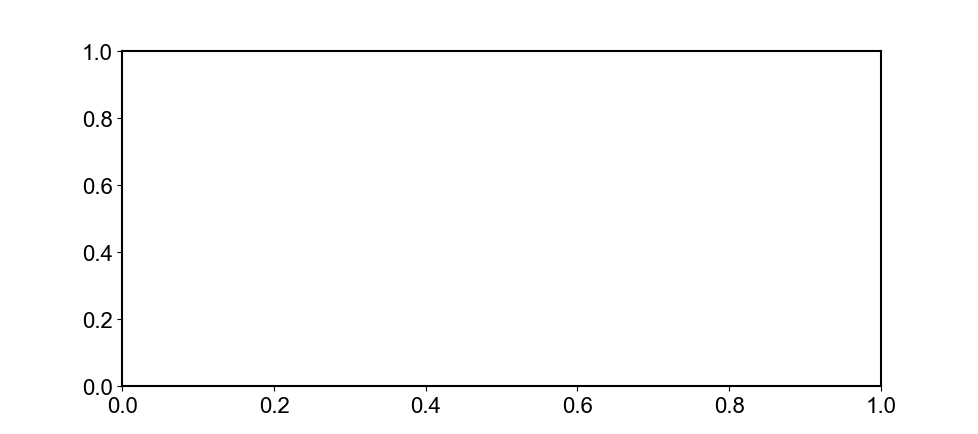

In [3]:
fig, ax = plt.subplots(figsize=(18*cm*figsize_conversion_coeff, 8*cm*figsize_conversion_coeff))

# Collect lda_probe values
lda_values = np.array([All_traces[key].lda_probe for key in All_traces])

# Colormap and normalization (explicit range)
cmap = plt.get_cmap('copper')
cmap = plt.get_cmap('RdBu')
cmap = plt.get_cmap('seismic')
#cmap = plt.get_cmap('twilight')
cmap = plt.get_cmap('RdBu_r')
norm = plt.Normalize(vmin=lda_values.min(), vmax=lda_values.max())

# Plot traces
for key in All_traces:
    trace = All_traces[key]
    print(trace.lda_probe)
    print(Data['AR4.5 - D2 zone 1']['acoustic']['Delta_T'][np.where(Data['AR4.5 - D2 zone 1']['acoustic']['lambda_probe']==trace.lda_probe)])
    ax.plot(
        trace.delay_tot,
        trace.DTT_tot*trace.dtt_to_sigma_ext_coeff,
        color=cmap(norm(trace.lda_probe))
    )

# Create a ScalarMappable for the colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])  # required for older matplotlib versions

# Add colorbar on the side, tied to ax
cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.02,      # distance from the plot
    fraction=0.05 # width of the colorbar
)

cbar.set_label(r'Wavelength (nm)', fontsize=28*fixed_factor)

ax.set_xlabel('Delay (ps)', fontsize=28*fixed_factor)
ax.set_ylabel(r'$\Delta \sigma_{\mathrm{ext}}$ (nm$^2$)', fontsize=28*fixed_factor)
ax.set_xlim( (-50, 550))



fig.set_size_inches((19*cm*figsize_conversion_coeff, 8*cm*figsize_conversion_coeff))
plt.tight_layout()
plt.show()


fig.patch.set_facecolor( '#FF000000' )

if saving_figures :
    os.chdir(dir_save_data)
    plt.savefig('All raw PaP signals - NDe thick sapphire.svg')
    plt.savefig('All raw PaP signals - NDe thick sapphire.png')

## All PaP signals together : ND2 zone1 on thick Silica studied in April 2026

In [4]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Silice thick 4,5 - D2 zone1\PaP_study'

os.chdir(dir_root)



# get calib
dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\2026-04'

Source_list = ['OPO', 'SHG']
FWHM_data = get_FWHM_data(dir_calib, Source_list)
WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_1D_mean']

WL_calib_probe, FWHM_calib_probe = WL_calib['OPO'], FWHM_calib['OPO']


## Get all traces
All_traces = {}


for root, dirs, files in os.walk(dir_root) :
    for dir in dirs :
        if dir.endswith('treated') :
            Trace_acoustic = get_PaP_dataset(dir_root + '\\' + dir, 'Trace_acoustic_fitted')
            Trace_acoustic.lda_probe = int(dir.split('_')[-2])


            #Get probe FWHM
            idx_fwhm_probe =  np.searchsorted(WL_calib_probe,Trace_acoustic.lda_probe)
            fwhm_probe = FWHM_calib_probe[idx_fwhm_probe]

            coeff = DTT_to_delta_sigma(1, fwhm_probe) 
            
            Trace_acoustic.dtt_to_sigma_ext_coeff = coeff
            print(Trace_acoustic.lda_probe, coeff)
            All_traces[Trace_acoustic.dir_name] = Trace_acoustic


640 -189513.15978932692
650 -196829.84188182733
590 -160188.77820316196
600 -163234.95725088243
610 -169090.4338772601
620 -171889.46652642364
580 -148577.27034522264
660 -207673.35496430311
670 -208145.3577734657
680 -207869.9899299711
690 -205655.44258301528
570 -143376.74634141297
630 -179771.5691192893
700 -205966.69726811253


In [7]:
Data={}
Data['AR4.5 - D2 zone 1'] = {}


Data['AR4.5 - D2 zone 1']['lda_SPR'] = 631e-9
Data['AR4.5 - D2 zone 1']['color'] = '#488f31'


dir_root_2 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Silice thick 4,5 - D2 zone1'
dir_root_treated_data_2 = dir_root_2 + r'\Extinction variation calculation'
dir_root_exp_traces_2 = dir_root_2 + r'\PaP_study'
dir_root_simul_data_2 = dir_root_2 + r'\Simulation results'
fname_acoustic_2 = 'Treated_acoustic_data'
fname_thermic_2 = 'Treated_thermic_data'

Data['AR4.5 - D2 zone 1'] = {}
Data['AR4.5 - D2 zone 1']['color'] = '#488f31'
Data['AR4.5 - D2 zone 1']['lda_SPR'] = 631e-9
Data['AR4.5 - D2 zone 1']['acoustic'] = get_treated_data_dictionnary_dataset(dir_root_treated_data_2, fname_acoustic_2)
Data['AR4.5 - D2 zone 1']['thermic']  = get_treated_data_dictionnary_dataset(dir_root_treated_data_2, fname_thermic_2)
Data['AR4.5 - D2 zone 1']['All traces'] = get_all_raw_traces(dir_root_exp_traces_2)
Data['AR4.5 - D2 zone 1']['All traces'] = reorder_all_traces_dic(Data['AR4.5 - D2 zone 1']['All traces'])
#Data['AR4.5 - D2 zone 1']['Simul_th'] = get_simulation_dsigma_thermic(dir_root_simul_data_2, 'd_sigma_simulation_thermic')

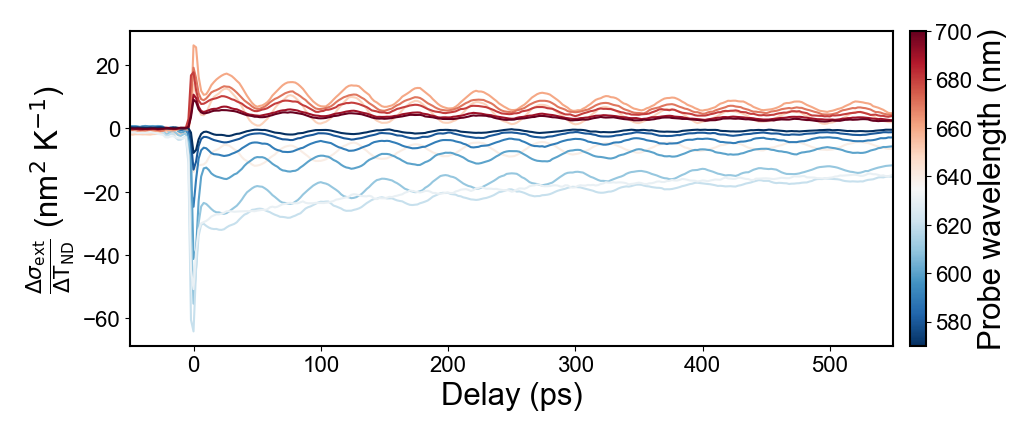

In [14]:
fig, ax = plt.subplots(figsize=(18*cm*figsize_conversion_coeff, 8*cm*figsize_conversion_coeff))

# Collect lda_probe values
lda_values = np.array([All_traces[key].lda_probe for key in All_traces])

# Colormap and normalization (explicit range)
#cmap = plt.get_cmap('copper')
#cmap = plt.get_cmap('RdBu')
#cmap = plt.get_cmap('seismic')
#cmap = plt.get_cmap('twilight')
cmap = plt.get_cmap('RdBu_r')
norm = plt.Normalize(vmin=lda_values.min(), vmax=lda_values.max())

# Plot traces
for key in All_traces:
    trace = All_traces[key]
    dT = Data['AR4.5 - D2 zone 1']['acoustic']['Delta_T'][np.where(Data['AR4.5 - D2 zone 1']['acoustic']['lambda_probe']==trace.lda_probe)][0]
    
    ax.plot(
        trace.delay_tot,
        trace.DTT_tot*trace.dtt_to_sigma_ext_coeff/dT*2.55,
        color=cmap(norm(trace.lda_probe))
    )

# Create a ScalarMappable for the colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])  # required for older matplotlib versions

# Add colorbar on the side, tied to ax
cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.02,      # distance from the plot
    fraction=0.05 # width of the colorbar
)

cbar.set_label(r'Probe wavelength (nm)', fontsize=28*fixed_factor)

ax.set_xlabel('Delay (ps)', fontsize=28*fixed_factor)
ax.set_ylabel(r'$\frac{\Delta \sigma_{\mathrm{ext}}}{\Delta \mathrm{T_{ND}}}$ (nm$^2$ K$^{-1}$)', fontsize=28*fixed_factor)
ax.set_xlim( (-50, 550))



fig.set_size_inches((19*cm*figsize_conversion_coeff, 8*cm*figsize_conversion_coeff))
plt.tight_layout()
plt.show()


fig.patch.set_facecolor( '#FF000000' )

if saving_figures :
    os.chdir(dir_save_data)
    plt.savefig('All raw PaP signals - ND2 zone1 thick silica.svg')
    plt.savefig('All raw PaP signals - ND2 zone1 thick silica.png')

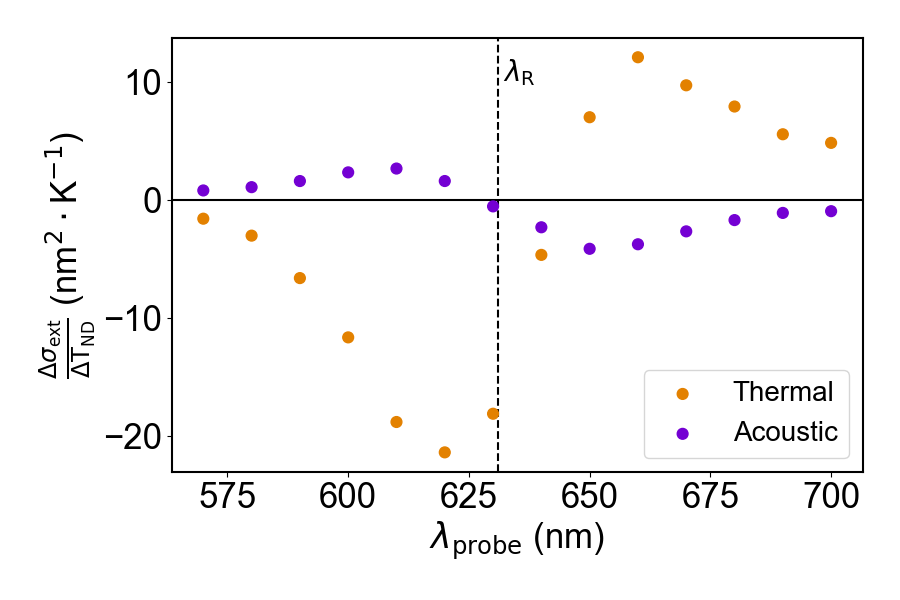

In [ ]:
mpl.rcParams["font.size"] = 25

Data={}


Data['AR4.5 - D2 zone 1'] = {}


Data['AR4.5 - D2 zone 1']['lda_SPR'] = 631e-9
Data['AR4.5 - D2 zone 1']['color'] = '#488f31'


dir_root_2 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Silice thick 4,5 - D2 zone1'
dir_root_treated_data_2 = dir_root_2 + r'\Extinction variation calculation'
dir_root_exp_traces_2 = dir_root_2 + r'\PaP_study'
dir_root_simul_data_2 = dir_root_2 + r'\Simulation results'
fname_acoustic_2 = 'Treated_acoustic_data'
fname_thermic_2 = 'Treated_thermic_data'

Data['AR4.5 - D2 zone 1'] = {}
Data['AR4.5 - D2 zone 1']['color'] = '#488f31'
Data['AR4.5 - D2 zone 1']['lda_SPR'] = 631e-9
Data['AR4.5 - D2 zone 1']['acoustic'] = get_treated_data_dictionnary_dataset(dir_root_treated_data_2, fname_acoustic_2)
Data['AR4.5 - D2 zone 1']['thermic']  = get_treated_data_dictionnary_dataset(dir_root_treated_data_2, fname_thermic_2)
Data['AR4.5 - D2 zone 1']['All traces'] = get_all_raw_traces(dir_root_exp_traces_2)
Data['AR4.5 - D2 zone 1']['All traces'] = reorder_all_traces_dic(Data['AR4.5 - D2 zone 1']['All traces'])
#Data['AR4.5 - D2 zone 1']['Simul_th'] = get_simulation_dsigma_thermic(dir_root_simul_data_2, 'd_sigma_simulation_thermic')


fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(Data['AR4.5 - D2 zone 1']['thermic']['lambda_probe'],Data['AR4.5 - D2 zone 1']['thermic']['Delta_sigma_th_normalized'],linestyle='', s=60, color = "#E38100", label='Thermal' )
#ax.errorbar(Data['AR2.3 - NDd zone 3']['thermic']['lambda_probe'],Data['AR2.3 - NDd zone 3']['thermic']['Delta_sigma_th_normalized'],linestyle='', yerr = np.abs(Data['AR2.3 - NDd zone 3']['thermic']['Delta_sigma_th_normalized_err']), color = "#ff0d0d" )

ax.scatter(Data['AR4.5 - D2 zone 1']['acoustic']['lambda_probe'],Data['AR4.5 - D2 zone 1']['acoustic']['Delta_sigma_ac_normalized'],linestyle='', s=60, color="#7400D3", label = 'Acoustic' )
#ax.errorbar(Data['AR2.3 - NDd zone 3']['acoustic']['lambda_probe'],Data['AR2.3 - NDd zone 3']['acoustic']['Delta_sigma_ac_normalized'],linestyle='', yerr = np.abs(Data['AR2.3 - NDd zone 3']['acoustic']['Delta_sigma_ac_normalized_err']), color = '#488f31' )

ax.axhline(0, color='black', zorder=0)
ax.axvline(Data['AR4.5 - D2 zone 1']['lda_SPR']*1e9, color = 'black', linestyle='--', zorder=0)

ax.set_xlabel(r'$\lambda_\mathrm{probe}$ (nm)')
ax.set_ylabel(r'$\frac{\Delta \sigma_\mathrm{ext}}{\Delta \mathrm{T}_\mathrm{ND}}$ (nm$^2 \cdot$K$^{-1}$)')
ax.text(0.48, 0.90, r'$\lambda_\mathrm{R}$', transform=ax.transAxes, fontsize=20)

#ax.annotate(text='', xy=(630,Data['AR2.3 - NDd zone 3']['thermic']['Delta_sigma_th_normalized'][5]+0.5), xytext=(630,0),arrowprops=dict(arrowstyle='<->', color="#E38100",linewidth=2.5))
#ax.text(590, 3, r'$\Delta \sigma_\mathrm{ext} / \Delta \mathrm{T_{ND}}$', color="#B97E00")

#ax.annotate(text='', xy=(630,-Data['AR2.3 - NDd zone 3']['acoustic']['Delta_sigma_ac_normalized'][4]), xytext=(630,0),arrowprops=dict(arrowstyle='<->', color="#B90900",linewidth=2.5))




fig.patch.set_facecolor( '#FF000000' )

#plt.xlim((550, 800))
plt.legend(fontsize=20, loc='lower right')
plt.tight_layout()


if saving_figures :
    os.chdir(dir_save_data)
    plt.savefig('Quantitative experimental amplitudes.svg')
    plt.savefig('Quantitative experimental amplitudes.png')

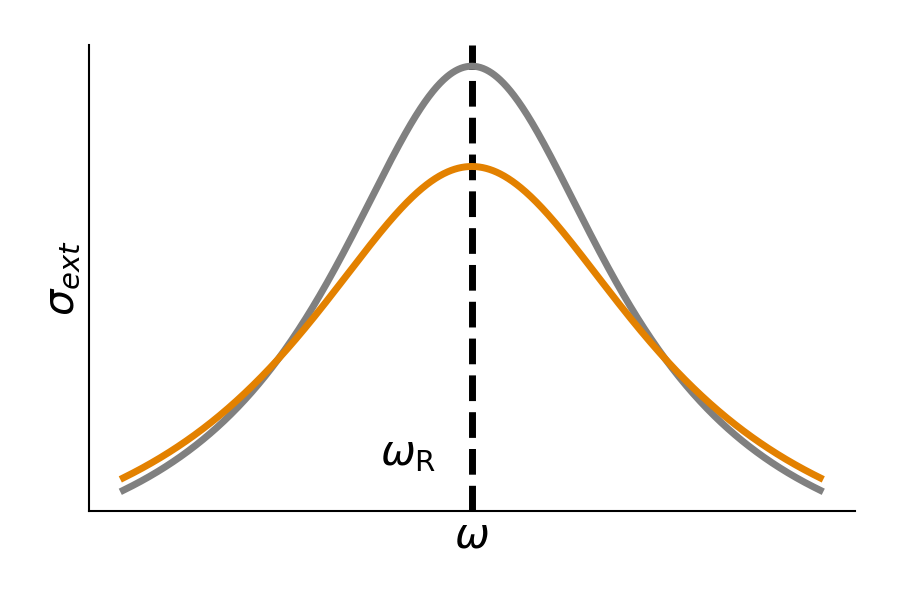

In [ ]:
mpl.rcParams["font.size"] = 30
fig, ax = plt.subplots(figsize=(9,6))



Energy = np.linspace(1.7, 2.3, 1000)

x_probe = Energy[450]
delta_w = 0.07
tau = 800/3

delta_Ec_thermic = 0.01
delta_Ec_thermic = 0.0

#Lorentzian shape for the SPR
A = 1
E_c = 2
w = 0.3
y0=0


ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks
ax.set_xlabel(r'$\omega$')
ax.set_ylabel(r'$\sigma_{ext}$')

ax.plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='grey', label ='SPR at equilibrium', linewidth=5)

ax.plot(Energy, Lorentz(Energy, E_c+ delta_Ec_thermic, w + delta_w, A, y0),color="#E38100", label = 'Thermal', linewidth=5)


#ax.annotate(text='', xy=(x_probe,Lorentz(x_probe, E_c, w, A, y0)), xytext=(x_probe,Lorentz(x_probe, E_c+ delta_Ec_thermic, w + delta_w, A, y0)),arrowprops=dict(arrowstyle='<->', color="#B97E00", linewidth=2.5))
#ax.text(x_probe-0.25, 3, r'$\Delta \sigma_\mathrm{ext}$', color="#B97E00")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.axvline(E_c, color='black', linestyle='--',zorder=0, linewidth=5)
ax.text(0.38, 0.1, r'$\omega_\mathrm{R}$', transform=ax.transAxes)
fig.patch.set_facecolor( '#FF000000' )

#plt.legend(fontsize=15)
plt.tight_layout()



if saving_figures :
    os.chdir(dir_save_data)
    plt.savefig('Simple scheme thermal variations.svg')
    plt.savefig('Simple scheme thermal variations.png')

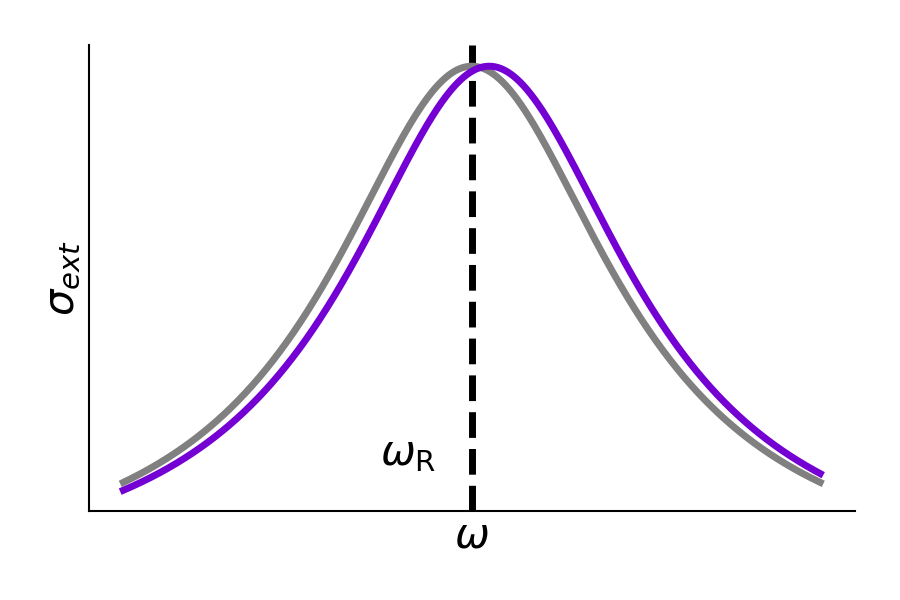

In [13]:
mpl.rcParams["font.size"] = 30
fig, ax = plt.subplots(figsize=(9,6))



Energy = np.linspace(1.7, 2.3, 1000)

x_probe = Energy[450]
delta_w = 0.07
tau = 800/3


delta_Ec_acoustic = 0.015
#Lorentzian shape for the SPR
A = 1
E_c = 2
w = 0.3
y0=0


ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks
ax.set_xlabel(r'$\omega$')
ax.set_ylabel(r'$\sigma_{ext}$')

ax.plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='grey', label ='SPR at equilibrium', linewidth=5)

ax.plot(Energy, Lorentz(Energy, E_c+ delta_Ec_acoustic, w, A, y0),color="#7400D3", label = 'Acoustic', linewidth=5)


#ax.annotate(text='', xy=(x_probe,Lorentz(x_probe, E_c, w, A, y0)), xytext=(x_probe,Lorentz(x_probe, E_c+ delta_Ec_thermic, w + delta_w, A, y0)),arrowprops=dict(arrowstyle='<->', color="#B97E00", linewidth=2.5))
#ax.text(x_probe-0.25, 3, r'$\Delta \sigma_\mathrm{ext}$', color="#B97E00")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# # make arrows
# ax.plot((1), (0), ls="", marker=">", ms=10, color="k",
#         transform=ax.get_yaxis_transform(), clip_on=False)
# ax.plot((0), (1), ls="", marker="^", ms=10, color="k",
#         transform=ax.get_xaxis_transform(), clip_on=False)



ax.axvline(E_c, color='black', linestyle='--',zorder=0, linewidth=5)
ax.text(0.38, 0.1, r'$\omega_\mathrm{R}$', transform=ax.transAxes)
fig.patch.set_facecolor( '#FF000000' )

#plt.legend(fontsize=15)
plt.tight_layout()



if saving_figures :
    os.chdir(dir_save_data)
    plt.savefig('Simple scheme acoustic variations.svg')
    plt.savefig('Simple scheme acoustic variations.png')

In [20]:
g1, g2, g3 = 0.7, 4.6, 7.3 #experimental value
g1, g2, g3 = 1.37, 3.29, 4.76 #theoretical value
T1, T2, T3 = 78, 295, 425
print((g3-g2)/(T3-T2))
print((g2-g1)/(T2-T1))
print((g3-g1)/(T3-T1))

0.011307692307692305
0.008847926267281106
0.009769452449567723


-7.16332466188096


(0.0, 4.9295)

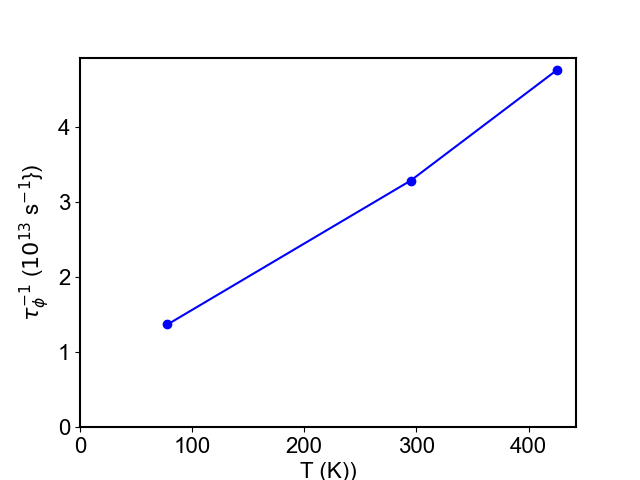

In [21]:
print(np.log10(2*np.pi*sc.constants.k*(600e-9)/(sc.constants.h*sc.constants.c))*2)

X = np.array([T1, T2, T3])
Y = np.array([g1, g2, g3])

fig, ax = plt.subplots()
ax.scatter(X, Y, color='blue')
ax.plot(X, Y, color='blue')
ax.set_ylabel(r'$\tau_{\phi}^{-1}$ ($10^{13}$ s$^{-1}$})')
ax.set_xlabel(r'T (K))')
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)